In [ ]:
import os
import pandas as pd
import urllib.request

RED_PATH = "/content/winequality-red.csv"
WHITE_PATH = "/content/winequality-white.csv"

# Ensure /content directory exists
os.makedirs("/content", exist_ok=True)

# Download the datasets if they do not exist
if not os.path.exists(RED_PATH):
    print("Downloading red wine dataset...")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv", RED_PATH)

if not os.path.exists(WHITE_PATH):
    print("Downloading white wine dataset...")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv", WHITE_PATH)

# Verify files are present
assert os.path.exists(RED_PATH), f"Red wine file not found: {RED_PATH}"
assert os.path.exists(WHITE_PATH), f"White wine file not found: {WHITE_PATH}"

# Read clean CSV files (semicolon-separated) for modeling
red_df = pd.read_csv(RED_PATH, sep=";")
white_df = pd.read_csv(WHITE_PATH, sep=";")

print("✅ Red wine dataset successfully verified and loaded:", red_df.shape)
print("✅ White wine dataset successfully verified and loaded:", white_df.shape)


✅ Red wine dataset successfully verified and loaded: (1599, 12)
✅ White wine dataset successfully verified and loaded: (4898, 12)


In [ ]:
!pip install catboost
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, roc_curve, auc)
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set global plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [ ]:
# ============================================================
# 0. Model Definitions
# ============================================================
from sklearn.ensemble import RandomForestClassifier


In [ ]:
# ============================================================
# 1. Training Procedure with Grid Search Optimisation
# ============================================================
import os
import time
from sklearn.model_selection import GridSearchCV

def train_one_model(X_res, y_res, X_test, y_test, device, n_classes, seed=42):
    # Print available CPU cores
    total_cores = os.cpu_count() or 1
    print(f"[System Info] Total CPU cores detected: {total_cores}. Running with n_jobs=-1 (using all cores).")

    # Base Random Forest configuration
    # We set n_jobs=1 here to avoid conflicts with GridSearchCV's n_jobs=-1
    base_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        class_weight="balanced",
        random_state=seed,
        n_jobs=1
    )

    # Try max_features values between 2 to 11
    param_grid = {
        "max_features": [2, 4, 6, 8, 11]
    }

    # Setup grid search with cv=10
    # n_jobs=-1 here will use all available cores at the hyperparameter search level
    search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    print(f"\n⏳ Running GridSearch CV=10 on Random Forest for Seed {seed}...")
    search.fit(X_res, y_res)

    print(f"[✅ Seed {seed} Trained] Best Parameters: {search.best_params_} | Best CV Score: {search.best_score_:.4f}")
    return search.best_estimator_, []

def train_ensemble(X_res, y_res, X_test, y_test, device, n_classes, seeds):
    # Start tracking total elapsed time here
    start_time = time.time()

    # Select the single best model across seeds
    best_acc = -1
    best_probs = None
    best_seed = None
    labels = y_test
    all_losses = []  # Empty as Random Forest does not produce epoch-wise training loss

    for i, seed in enumerate(seeds):
        print(f"\n--- Training Random Forest {i+1}/{len(seeds)} (Seed: {seed}) ---")
        model, _ = train_one_model(X_res, y_res, X_test, y_test, device, n_classes, seed=seed)
        probs = model.predict_proba(X_test)
        preds = probs.argmax(axis=1)
        acc = accuracy_score(y_test, preds)
        print(f"[Evaluation] RF with Seed {seed} achieved Test Accuracy: {acc:.4f}")

        # Track the model with the highest validation/test accuracy
        if acc > best_acc:
            best_acc = acc
            best_probs = probs
            best_seed = seed

    # End tracking total elapsed time here
    elapsed_time = time.time() - start_time
    elapsed_minutes = int(elapsed_time // 60)
    elapsed_seconds = int(elapsed_time % 60)
    print(f"\n⏱️ Total Training Time across all seeds: {elapsed_minutes}m {elapsed_seconds}s")

    print(f"\n✨ Selected the best single Random Forest model with Seed: {best_seed} (Accuracy: {best_acc:.4f})")

    return best_probs, labels, all_losses

In [ ]:
# ============================================================
# 2. Decision Boundary / Threshold Optimisation
# ============================================================
def threshold_optimize(probs, labels, n_classes):
    if n_classes == 2:
        best_f1, best_t, best_preds = 0, None, None
        for t in np.arange(0.2, 0.8, 0.02):
            preds = (probs[:, 1] > t).astype(int)
            f1 = f1_score(labels, preds, average='macro')
            if f1 > best_f1:
                best_f1, best_t, best_preds = f1, t, preds
        return best_preds
    else:
        best_f1, best_preds = 0, None
        for t_low in np.arange(0.2, 0.8, 0.05):
            for t_high in np.arange(0.2, 0.8, 0.05):
                preds = np.where(probs[:, 0] > t_low, 0, np.where(probs[:, 2] > t_high, 2, 1))
                f1 = f1_score(labels, preds, average='macro')
                if f1 > best_f1:
                    best_f1, best_preds = f1, preds
        return best_preds


In [ ]:
# ============================================================
# 3. High-Quality Data Visualisation Helpers
# ============================================================
def plot_balance_distribution(y_orig, y_res, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(x=y_orig, ax=axes[0], palette="Blues_d")
    axes[0].set_title(f"{name} - Original Distribution", fontsize=14, fontweight="bold")
    axes[0].set_xlabel("Class Label")
    axes[0].set_ylabel("Count")
    for p in axes[0].patches:
        axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)

    sns.countplot(x=y_res, ax=axes[1], palette="Oranges_d")
    axes[1].set_title(f"{name} - After SMOTE", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Class Label")
    axes[1].set_ylabel("Count")
    for p in axes[1].patches:
        axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(labels, preds, n_classes, name):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False,
                xticklabels=[f"Class {i}" for i in range(n_classes)],
                yticklabels=[f"Class {i}" for i in range(n_classes)])
    plt.title(f"{name} - Confusion Matrix (Optimized)", fontsize=14, fontweight="bold")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

def plot_roc_curves(labels, probs, n_classes, name):
    plt.figure(figsize=(7, 6))
    if n_classes == 2:
        fpr, tpr, _ = roc_curve(labels, probs[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
    else:
        from sklearn.preprocessing import label_binarize
        y_bin = label_binarize(labels, classes=range(n_classes))
        colors = ["aqua", "darkorange", "cornflowerblue"]
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=colors[i], lw=2, label=f"Class {i} (AUC = {roc_auc:.4f})")

    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} - ROC Curves", fontsize=14, fontweight="bold")
    plt.legend(loc="lower right")
    plt.show()

def plot_loss_curves(all_losses, name):
    if len(all_losses) == 0:
        return
    plt.figure(figsize=(8, 4))
    for i, loss in enumerate(all_losses):
        plt.plot(loss, label=f"Seed {i+1}", alpha=0.7)
    plt.title(f"{name} - Training Loss Across Multiple Seeds", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Focal Loss")
    plt.legend()
    plt.show()

In [ ]:
# ============================================================
# 4. Core Execution Pipeline
# ============================================================
def run_variety(df, name, n_classes, device, seeds=(42, 123, 2024, 7, 99)):
    print("\n" + "=" * 60)
    print(f"  {name} Wine —— SMOTE on Raw Quality (With Data Leakage)")
    print("=" * 60)

    df = df.copy()

    # Raw target for SMOTE on individual quality values (e.g., 3 to 9)
    y_raw = df["quality"].values.astype(np.int64)

    feature_cols = [c for c in df.columns if c not in ["quality", "label"]]
    X = df[feature_cols].values.astype(np.float32)
    y_reg = df["quality"].values.astype(np.float32)

    X_aug = X # Use original features only

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_aug).astype(np.float32)

    # Configure SMOTE for each raw quality level
    counts = np.bincount(y_raw)
    valid_classes = np.where(counts > 0)[0]
    max_count = counts.max()

    # UPDATED: Oversample all valid classes to match the true maximum count
    sampling_strategy = {c: max(counts[c], max_count) for c in valid_classes}

    min_count = counts[counts > 0].min()
    k_neighbors = max(1, min(5, min_count - 1))

    smt = SMOTE(random_state=42, sampling_strategy=sampling_strategy, k_neighbors=k_neighbors)

    # Apply SMOTE to the entire dataset (Leakage occurs here)
    X_res, y_res_raw = smt.fit_resample(X_scaled, y_raw)

    # Visualising distribution of raw quality values after SMOTE
    plt.figure(figsize=(8, 5))
    ax = sns.countplot(x=y_res_raw, palette="viridis")
    plt.title(f"{name} - Raw Quality Distribution After SMOTE (3-9)", fontsize=14, fontweight="bold")
    plt.xlabel("Raw Wine Quality Score")
    plt.ylabel("Count")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # Convert the resampled raw quality scores to target class buckets for the models
    if n_classes == 2:
        y_res = (y_res_raw >= 7).astype(np.int64)
        y_orig_mapped = (y_raw >= 7).astype(np.int64)
    else:
        y_res = np.array([0 if q <= 4 else (1 if q <= 6 else 2) for q in y_res_raw], dtype=np.int64)
        y_orig_mapped = np.array([0 if q <= 4 else (1 if q <= 6 else 2) for q in y_raw], dtype=np.int64)

    # Split into train/test sets after data synthesis has happened on the full dataset
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_res, y_res, test_size=0.2, stratify=y_res, random_state=42)

    # Correctly pass original mapped labels vs balanced labels to compare distributions
    plot_balance_distribution(y_orig_mapped, y_res, name)

    # Train the ensemble models
    avg_probs, labels, all_losses = train_ensemble(X_tr, y_tr, X_te, y_te, device, n_classes, seeds)
    preds_opt = threshold_optimize(avg_probs, labels, n_classes)

    acc_final = accuracy_score(labels, preds_opt)
    f1_final = f1_score(labels, preds_opt, average="macro")
    try:
        if n_classes > 2:
            auc_score = roc_auc_score(labels, avg_probs, multi_class="ovr", average="macro")
        else:
            auc_score = roc_auc_score(labels, avg_probs[:, 1])
    except:
        auc_score = float("nan")

    print(f"\n[Final Performance] Acc={acc_final:.4f} | F1={f1_final:.4f} | AUC={auc_score:.4f}")

    plot_confusion_matrix(labels, preds_opt, n_classes, name)
    plot_roc_curves(labels, avg_probs, n_classes, name)
    plot_loss_curves(all_losses, name)

    return {"name": name, "n_classes": n_classes, "n_test": len(y_te),
            "acc": acc_final, "f1": f1_final, "auc": auc_score}


✅ GPU detected successfully: NVIDIA L4

  Red Wine Wine —— SMOTE on Raw Quality (With Data Leakage)


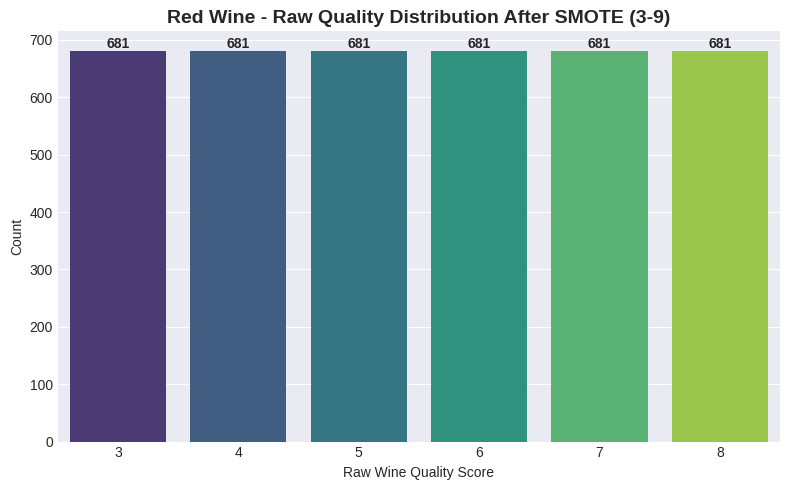

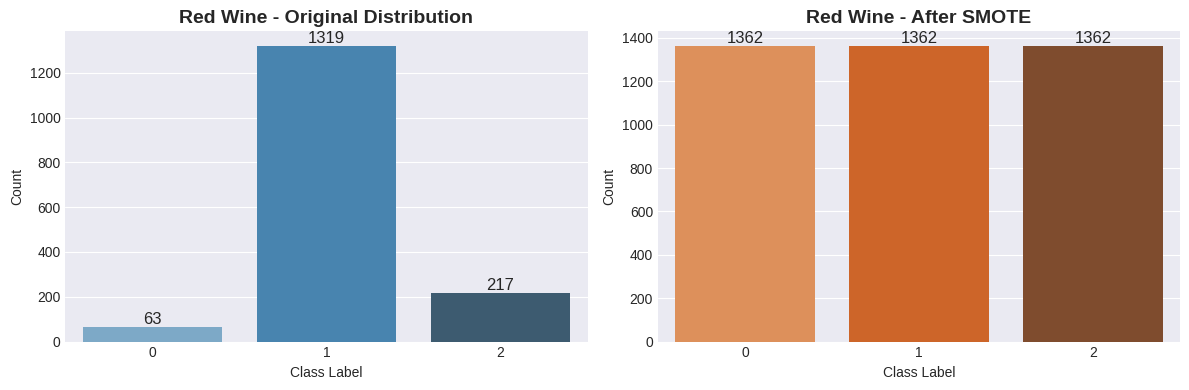


--- Training Random Forest 1/5 (Seed: 42) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on Random Forest for Seed 42...
[✅ Seed 42 Trained] Best Parameters: {'max_features': 2} | Best CV Score: 0.9360
[Evaluation] RF with Seed 42 achieved Test Accuracy: 0.9254

--- Training Random Forest 2/5 (Seed: 123) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on Random Forest for Seed 123...
[✅ Seed 123 Trained] Best Parameters: {'max_features': 2} | Best CV Score: 0.9360
[Evaluation] RF with Seed 123 achieved Test Accuracy: 0.9230

--- Training Random Forest 3/5 (Seed: 2024) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on Random Forest for Seed 2024...
[✅ Seed 2024 Trained] Best Parameters: {'max_features': 2} | Best CV Score: 0.9345
[Evaluation] RF with Seed 2024 achieved Test Acc

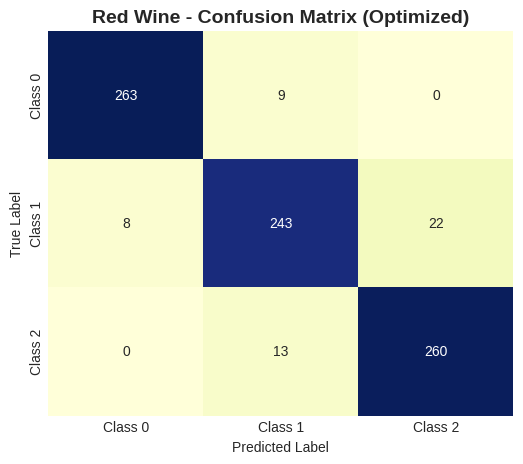

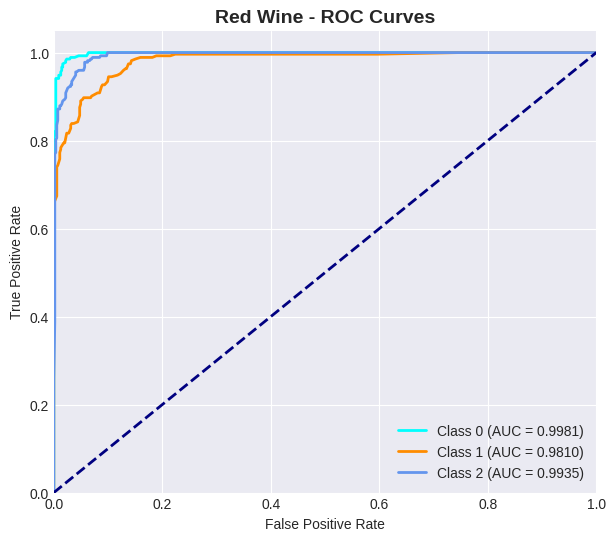


  White Wine Wine —— SMOTE on Raw Quality (With Data Leakage)


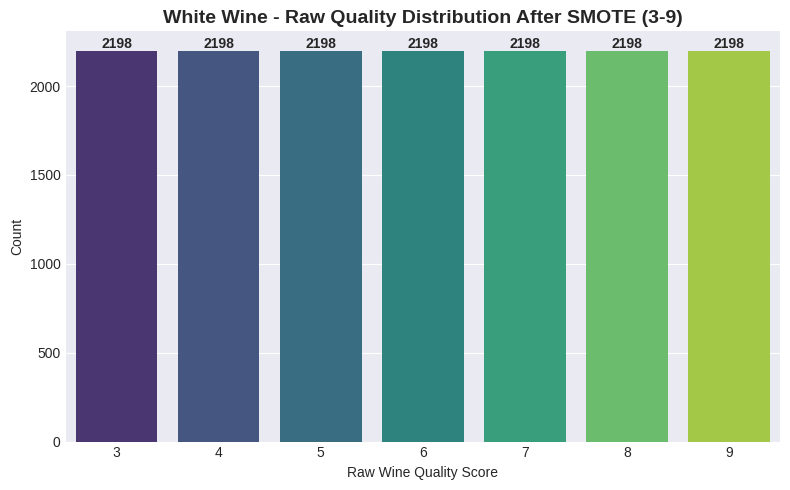

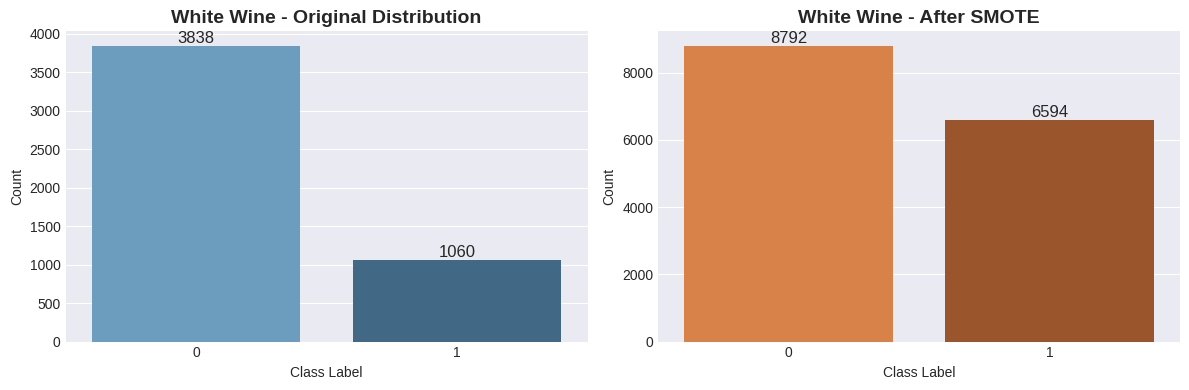


--- Training Random Forest 1/5 (Seed: 42) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on Random Forest for Seed 42...
[✅ Seed 42 Trained] Best Parameters: {'max_features': 2} | Best CV Score: 0.9576
[Evaluation] RF with Seed 42 achieved Test Accuracy: 0.9643

--- Training Random Forest 2/5 (Seed: 123) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on Random Forest for Seed 123...
[✅ Seed 123 Trained] Best Parameters: {'max_features': 2} | Best CV Score: 0.9586
[Evaluation] RF with Seed 123 achieved Test Accuracy: 0.9662

--- Training Random Forest 3/5 (Seed: 2024) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on Random Forest for Seed 2024...
[✅ Seed 2024 Trained] Best Parameters: {'max_features': 2} | Best CV Score: 0.9576
[Evaluation] RF with Seed 2024 achieved Test Acc

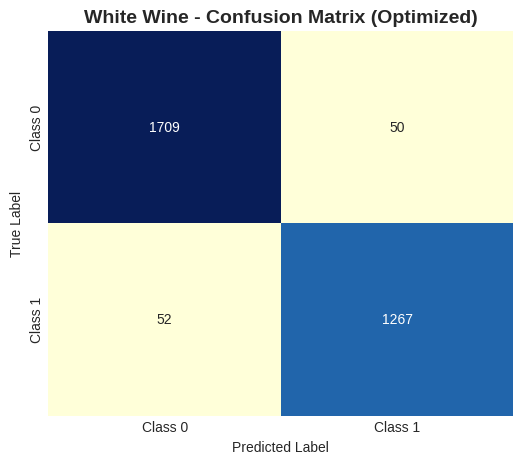

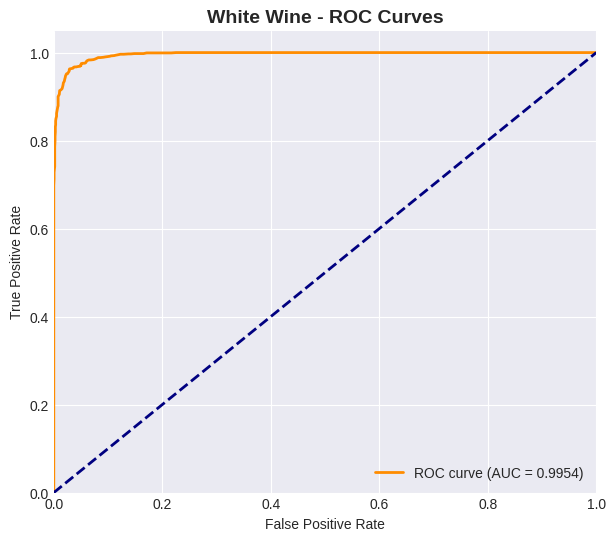


  Generating overall model performance summary plot...


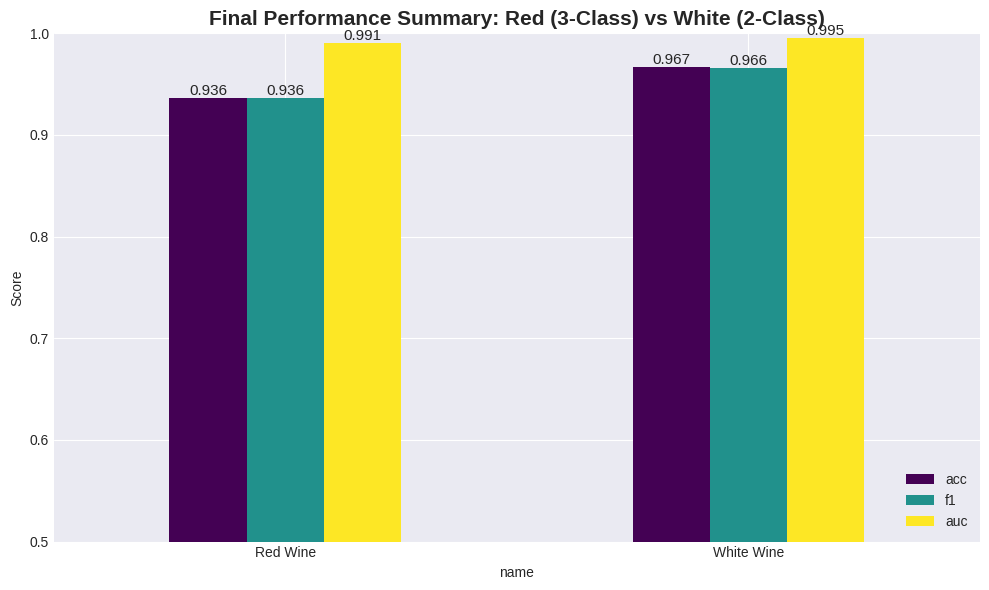

                 acc        f1       auc
name                                    
Red Wine    0.936430  0.936325  0.990870
White Wine  0.966862  0.966164  0.995373


In [ ]:
# ============================================================
# 7. Main Execution
# ============================================================
if __name__ == "__main__":
    red_df = pd.read_csv("/content/winequality-red.csv", sep=";")
    white_df = pd.read_csv("/content/winequality-white.csv", sep=";")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"\n✅ GPU detected successfully: {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device("cpu")
        print("\n❌ GPU not detected. Training with CPU.")

    # Run Red Wine (3-Class Classification)
    r_red = run_variety(red_df, "Red Wine", n_classes=3, device=device)

    # Run White Wine (2-Class Classification)
    r_white = run_variety(white_df, "White Wine", n_classes=2, device=device)

    # Generate and plot performance comparison bar chart
    print("\n" + "=" * 60)
    print("  Generating overall model performance summary plot...")
    summary_df = pd.DataFrame([r_red, r_white]).set_index("name")[["acc", "f1", "auc"]]

    ax = summary_df.plot(kind="bar", figsize=(10, 6), colormap="viridis", rot=0)
    plt.title("Final Performance Summary: Red (3-Class) vs White (2-Class)", fontsize=15, fontweight="bold")
    plt.ylabel("Score")
    plt.ylim(0.5, 1.0)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=11)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    print(summary_df)